# Проект: **КЛАССИФИКАЦИЯ В БАНКОВСКОЙ СФЕРЕ**

In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

### 1.0 Загрузка библиотек и модулей

In [ ]:
# --- Сторонние библиотеки ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn import preprocessing
from sklearn import model_selection
from sklearn import tree
from sklearn import ensemble
from sklearn import metrics
from sklearn import feature_selection
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from datetime import datetime
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, classification_report, accuracy_score, make_scorer
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.feature_selection import RFE
import optuna
import joblib
import json

# --- Мои собственные модули ---
from src.data_utils import load_data
from src.experiment_logger import log_experiment, save_plot
from src.features import (
                        outliers_iqr_mod,
                        create_marketing_features
                        )

### 1.1 Загрузка данных

In [3]:
df = load_data() 

print(df.shape)
df.head()

(11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,"2 343,00 $",yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,"45,00 $",no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,"1 270,00 $",yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,"2 476,00 $",yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,"184,00 $",no,no,unknown,5,may,673,2,-1,0,unknown,yes


### 1.2 Удаление пропусков и выбросов

In [4]:
# Проверка на явные пропуски
cols_null_percent = df.isnull().mean() * 100
cols_with_null = cols_null_percent[cols_null_percent>0].sort_values(ascending=False)
if cols_with_null.empty:
    print("Пропусков в датасете нет.")
else:
    print("Столбцы с пропусками (в процентах):")
    print(cols_with_null)

Столбцы с пропусками (в процентах):
balance    0.223974
dtype: float64


In [5]:
# преобразуем признак balance таким образом, чтобы он корректно считывался, как вещественное число (float)
df['balance'] = (df['balance']
                 .astype(str)
                 .str.replace(',', '.')
                 .str.replace(' ', '')
                 .str.rstrip('$€£')          # удаляем указанные символы с конца
                 .astype(float))

In [6]:
# обработаем пропуски в признаки balance , заменив их на медианные значения по данному признаку
df['balance'].fillna(df['balance'].median(), inplace=True)

In [7]:
# пропуски в ряде признаков заменены на "unknown". Поймем сколько их
unknown_counts = (df == "unknown").sum()

# Оставляем только те колонки, где есть хотя бы один "unknown"
unknown_cols = unknown_counts[unknown_counts > 0]

print(unknown_cols)

job            70
education     497
contact      2346
poutcome     8326
dtype: int64


Пропуски в типе контакта с клиентом и результаты прошлой маркетинговой компании, записанные словом "unknown" оставим в явном виде для последующей кодировки

In [8]:
# обработаем пропуски в категориальных признаках: job и education, заменив их на модальные значения
mask = (df['job'] == df['job'].value_counts().index[-1])
df.loc[mask, 'job'] = df['job'].mode()[0]

mask = (df['education'] == 'unknown')
df.loc[mask, 'education'] = df['education'].mode()[0]

In [9]:
# Ищем выбросы в balance
outliers, cleaned_df, lower_bound, upper_bound = outliers_iqr_mod(df, 'balance')

print(f'Нижняя граница: {round(lower_bound)}')
print(f'Верхняя граница: {round(upper_bound)}')
print(f'Число выбросов: {outliers.shape[0]}')
print(f'Результирующее число записей: {cleaned_df.shape[0]}')

Нижняя граница: -2241
Верхняя граница: 4063
Число выбросов: 1058
Результирующее число записей: 10104


In [10]:
# Из оставшихся числовых признаков стоит проверить на выбросы только возраст
cleaned_df['age'].describe()

count    10104.000000
mean        40.895487
std         11.735511
min         18.000000
25%         32.000000
50%         38.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

Явных выбросов в этом признаке нет

---

### 2.0 Разведывательный анализ

deposit
no     0.54
yes    0.46
Name: proportion, dtype: float64

График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_class_balance\plots\20261013_125106_class_distribution.png
Количество клиентов открывших депозит: 4681


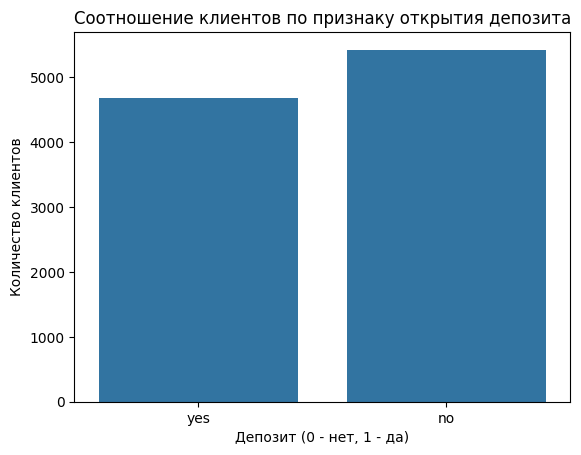

In [11]:
# Посмотрм на соотношение классов в данных на предмет несбалансированности

# Выведем процентное соотношение классов в признаке deposit
display(round(cleaned_df['deposit'].value_counts(normalize=True), 2))

# Построим диаграмму соотношения классов в признаке deposit
ax = sns.countplot(data=cleaned_df, x='deposit')
ax.set_title('Соотношение клиентов по признаку открытия депозита')
ax.set_xlabel('Депозит (0 - нет, 1 - да)')
ax.set_ylabel('Количество клиентов')
fig = plt.gcf()
plot_path = save_plot(fig, experiment_name="eda_class_balance", plot_name="class_distribution")
print(f"График сохранён: {plot_path}")

print(f"Количество клиентов открывших депозит: {cleaned_df[cleaned_df['deposit'] == 'yes']['deposit'].count()}")

,age,balance,day,duration,campaign,pdays,previous
count,10104.000000,10104.000000,10104.000000,10104.000000,10104.000000,10104.000000,10104.000000
mean,40.895487,807.331354,15.590657,368.777712,2.516924,51.307700,0.816112
std,11.735511,993.673452,8.441852,346.650712,2.707180,109.643031,2.243875
min,18.000000,-2049.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,95.000000,8.000000,137.000000,1.000000,-1.000000,0.000000
50%,38.000000,444.500000,15.000000,252.000000,2.000000,-1.000000,0.000000
75%,48.000000,1224.750000,22.000000,490.000000,3.000000,2.000000,1.000000
max,95.000000,4062.000000,31.000000,3881.000000,43.000000,854.000000,58.000000


График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_num_features\plots\20261013_125111_hist_box_all.png
Максимальный возраст клиента банка: 95 лет
Минимальная продолжительность разговора с клиентом банка: 2 секунды


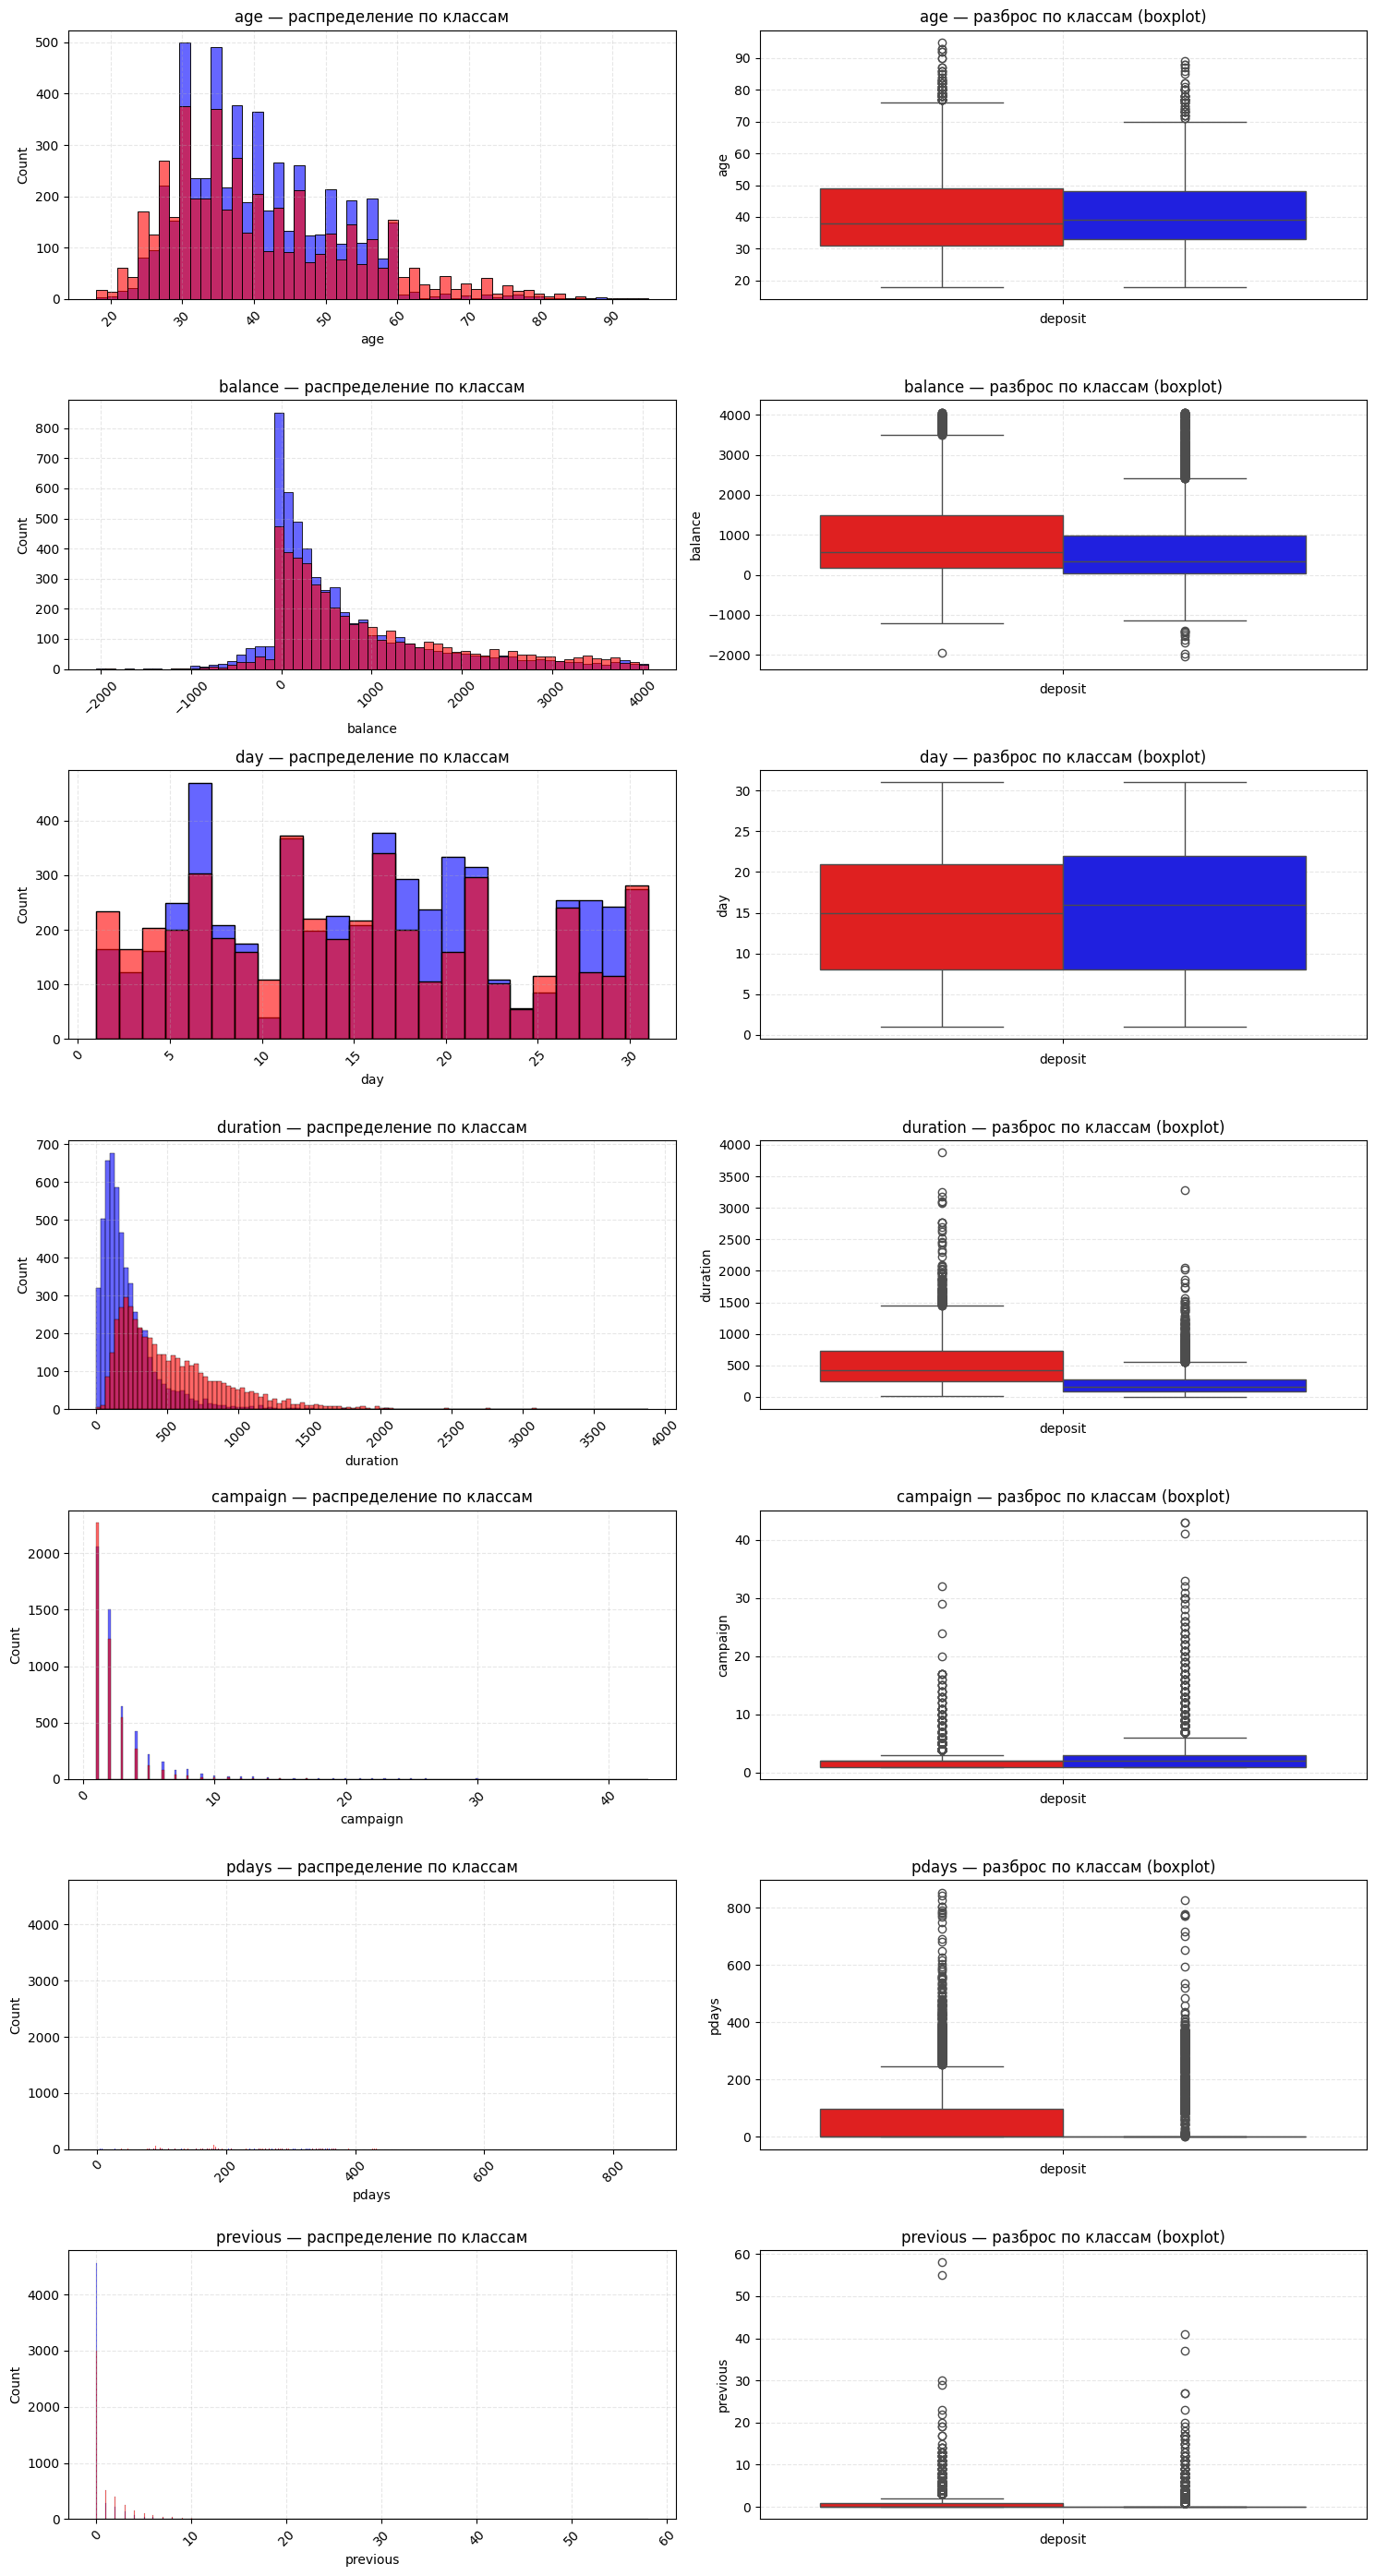

In [12]:
# Рассчитаем описательные статистики для количественных переменных

display(cleaned_df.describe())

# Выделяем имена числовых признаков
types = cleaned_df.dtypes
num_features = list(types[(types != 'object') & (types != 'category')].index)

n = len(num_features)
fig, axes = plt.subplots(n, 2, figsize=(15, 4 * n))

for i, feature in enumerate(num_features):
    # --- Гистограмма с разделением по классу ---
    ax_hist = axes[i][0]
    sns.histplot(
        data=cleaned_df,
        x=feature,
        hue='deposit',
        palette=['red', 'blue'],
        stat='count',
        common_norm=False,
        alpha=0.6,
        ax=ax_hist,
        legend=False  
    )
    ax_hist.set_title(f'{feature} — распределение по классам')
    ax_hist.grid(True, linestyle='--', alpha=0.3)
    ax_hist.tick_params(axis='x', rotation=45)

    # --- Boxplot: используем hue, чтобы корректно задать палитру ---
    ax_box = axes[i][1]
    sns.boxplot(
        data=cleaned_df,
        y=feature,
        hue='deposit',          
        palette=['red', 'blue'],
        ax=ax_box,
        dodge=True               
    )
    ax_box.set_xlabel('deposit')
    ax_box.set_title(f'{feature} — разброс по классам (boxplot)')
    ax_box.grid(True, linestyle='--', alpha=0.3)
    ax_box.get_legend().remove()  

plt.tight_layout()
plot_path = save_plot(fig, experiment_name="eda_num_features", plot_name="hist_box_all")

print(f"График сохранён: {plot_path}")
print(f"Максимальный возраст клиента банка: {cleaned_df['age'].max()} лет")
print(f"Минимальная продолжительность разговора с клиентом банка: {cleaned_df['duration'].min()} секунды")

>**Выводы из графиков**:

```Распределение age``` унимодальное, пик — 30–35 лет; правый хвост до 90+ лет — редкие наблюдения.
* По гистограмме: в классе «нет депозита» (тёмно‑бордовый) доля клиентов старше 50 лет выше, чем в классе «есть депозит» (синий).
* По boxplot: медианы age в обоих классах близки (~40 лет), межквартильные размахи сопоставимы; выбросы — в основном в верхней части шкалы (возраст >75–80 лет).
* Различий в центральной тенденции между классами практически нет; дифференциация проявляется в хвостах распределения (молодые чаще открывают депозит).
* Выбросы в age (90+) — кандидаты на проверку на ошибки ввода; при подтверждении реальности — рассмотреть флаг «возраст >75» вместо удаления.

```Распределение balance``` сильно скошено вправо; пик — вблизи 0, значительная доля наблюдений — с отрицательным балансом.
* По гистограмме: в классе «есть депозит» (синий) выше доля клиентов с балансом ≈0 и умеренно положительным; в классе «нет депозита» (бордовый) — более выраженный хвост в положительную область и заметная доля отрицательных значений.
* По boxplot: медиана balance в классе «есть депозит» выше, чем в классе «нет депозита»; межквартильный размах шире у класса «нет депозита».
* Выбросы (точки и удлинённые усы) — в обеих группах, в т. ч. экстремальные положительные и отрицательные значения; требуют проверки на корректность.
* Признак информативен для классификации: наблюдается различие в центральных тенденциях и форме распределения между классами.

```Распределение day``` — дискретное, диапазон 0–31; пики — на 7‑й и 12‑й день, далее — более равномерное заполнение.
* По гистограмме: в классе «есть депозит» (синий) выше доля контактов в первые 7 дней; в классе «нет депозита» (бордовый) — более равномерное распределение по дням, заметный пик на 12‑й день.
* По boxplot: медианы близки (≈15–16 день), но межквартильный размах у класса «есть депозит» смещён левее (более ранние контакты), у класса «нет депозита» — шире и смещён правее.
* Выбросов практически нет; разброс значений укладывается в типичные границы для признака «день последнего контакта».
* Признак потенциально информативен: клиенты, открывшие депозит, чаще контактировали в начале кампании.

```Распределение duration``` сильно скошено вправо; пик — вблизи 0 сек, далее — быстрый спад плотности.
* По гистограмме: в классе «есть депозит» (синий) выше доля коротких контактов (0–200 сек); в классе «нет депозита» (бордовый) — более выраженный хвост (длительные контакты).
* По boxplot: медиана duration в классе «есть депозит» существенно ниже, чем в классе «нет депозита»; межквартильный размах у класса «нет депозита» шире.
* Выбросы — в обеих группах, в т. ч. экстремальные значения >2500 сек; требуют проверки на корректность (ошибки фиксации, аномальные сессии).
* Признак информативен: клиенты, открывшие депозит, чаще имели короткие контакты; длительные разговоры ассоциированы с отсутствием депозита.

```Распределение campaign``` резко скошено вправо; подавляющая доля наблюдений — 0–3 контакта, далее — быстрое снижение частоты.
* По гистограмме: в классе «есть депозит» (синий) выше доля клиентов с 0–1 контактом; в классе «нет депозита» (бордовый) — более выраженные хвосты (3+ контакта).
* По boxplot: медианы в обоих классах близки к 0; межквартильный размах у класса «нет депозита» шире, у класса «есть депозит» — сжат к нулю.
* Выбросы — в обеих группах (значения >15–40 контактов); требуют проверки на корректность (ошибки учёта, аномальные клиенты).
* Признак информативен: клиенты, открывшие депозит, чаще имели минимальное число контактов; повторные контакты ассоциированы с отсутствием депозита.

```Распределение pdays``` дискретное, сильно скошено вправо; основная масса наблюдений — в диапазоне 0–200 дней, далее — редкие значения до 800+ дней.
* По гистограмме: в классе «нет депозита» (бордовый) — подавляющее большинство наблюдений; в классе «есть депозит» (синий) — единичные случаи, сконцентрированы в левой части (меньшие значения pdays).
* По boxplot: медиана pdays в классе «есть депозит» близка к 0; в классе «нет депозита» — существенно выше (≈250–300 дней); межквартильный размах у класса «нет депозита» шире.
* Выбросы — в классе «нет депозита» (значения >400–800 дней); требуют проверки на корректность (аномальные интервалы, ошибки учёта).
* Признак информативен: клиенты, открывшие депозит, чаще контактировали в рамках текущей кампании при малом числе пропущенных дней с предыдущей; длительные перерывы ассоциированы с отсутствием депозита.

```Распределение previous``` резко скошено вправо; подавляющая доля наблюдений — 0 контактов, далее — быстрое снижение частоты (единичные случаи при 1–60 контактах).
* По гистограмме: в классе «есть депозит» (синий) — почти исключительно 0 контактов; в классе «нет депозита» (бордовый) — небольшая доля наблюдений с 1+ контактами.
* По boxplot: медиана previous в классе «есть депозит» равна 0; в классе «нет депозита» — незначительно выше 0; межквартильный размах у класса «нет депозита» шире.
* Выбросы — в классе «нет депозита» (значения до 50–60 контактов); требуют проверки на корректность (аномальные клиенты, ошибки учёта).
* Признак информативен: клиенты, открывшие депозит, практически не имели контактов до текущей кампании; наличие предыдущих контактов ассоциировано с отсутствием депозита.

,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
count,10104,10104,10104,10104,10104,10104,10104,10104,10104,10104
unique,11,3,3,2,2,2,3,12,4,2
top,management,married,secondary,no,no,no,cellular,may,unknown,no
freq,2314,5714,5517,9938,5243,8711,7282,2616,7570,5423


График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_cat_features\plots\20261013_125119_hist_box_all.png
Количество месяцев в которые проводилась маркетинговая кампания: 12
Количество сфер занятости среди клиентов банка: 11


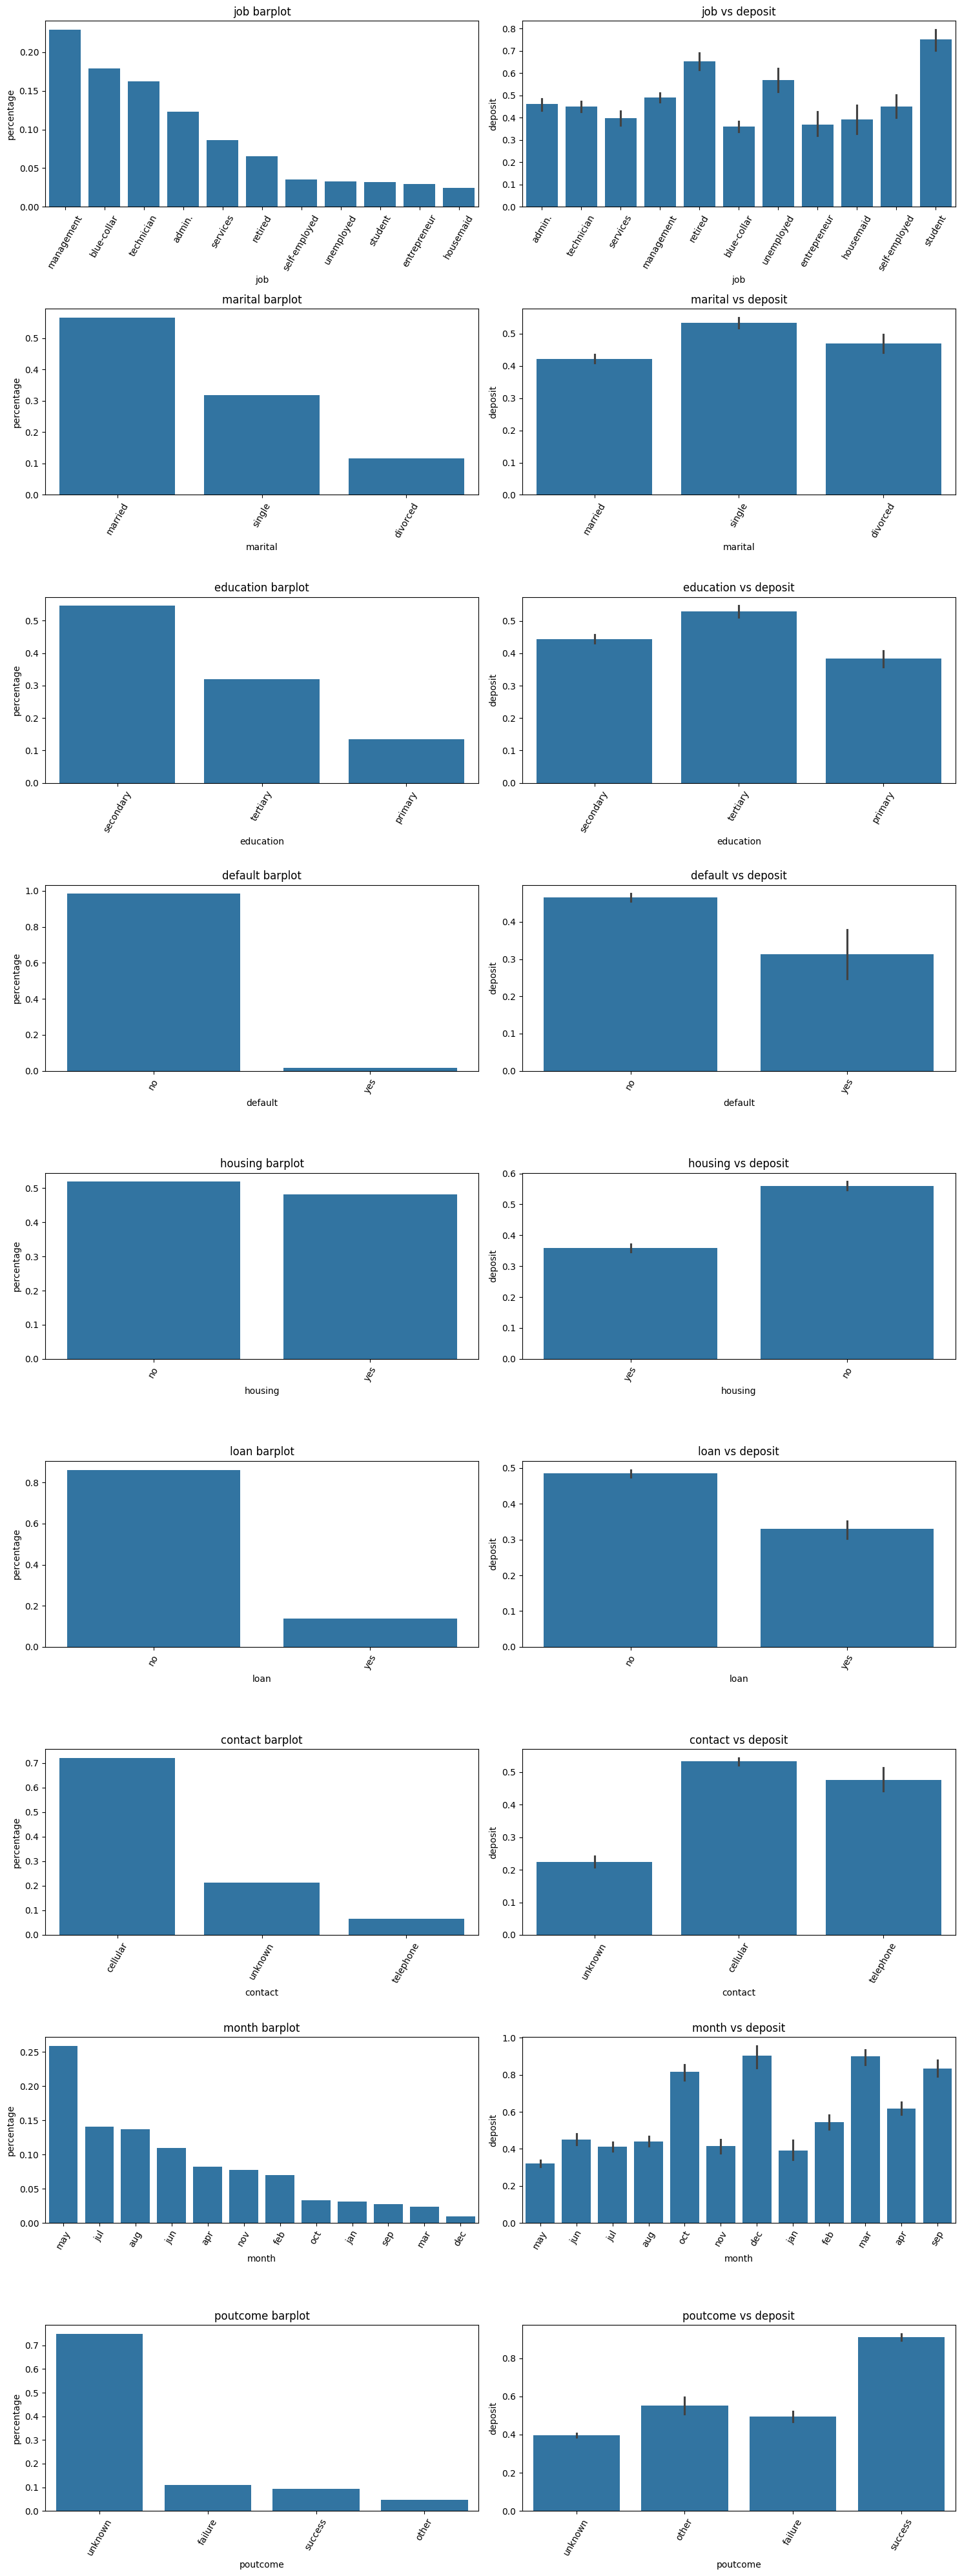

In [13]:
# Рассчитаем описательные статистики для категориальных переменных
display(cleaned_df.describe(include='object'))

# Выделяем имена категориальных признаков в виде списка для удобства дальнейшей работы
types = cleaned_df.dtypes
cat_features = list(types[(types == 'object')].index)

# Уберем целевой признак из списка
cat_features = cat_features[:-1]

# Заменим значения целевого признака на числовые для построения визуализации
data = cleaned_df.copy()
data['deposit'] = data['deposit'].apply(lambda x: 1 if x == 'yes' else 0)


n = len(cat_features)
fig, axes = plt.subplots(n, 2, figsize=(15, 40))

# Создаём цикл для всех признаков из списка категориальных признаков
for i, feature in enumerate(cat_features):
    # Строим количественную столбчатую диаграмму для долевого соотношения каждой из категорий в данных
    count_data = (cleaned_df[feature].value_counts(normalize=True)
                  .sort_values(ascending=False)
                  .rename('percentage')
                  .reset_index())
    count_barplot = sns.barplot(data=count_data, x=feature, y='percentage', ax=axes[i][0])
    count_barplot.set_title('{} barplot'.format(feature));
    count_barplot.xaxis.set_tick_params(rotation=60)
    
    # Строим столбчатую диаграмму доли людей открывших депозит (среднее по столбцу deposit) в зависимости от категории
    mean_barplot = sns.barplot(data=data, x=feature, y='deposit', ax=axes[i][1])
    mean_barplot.set_title('{} vs deposit'.format(feature));
    mean_barplot.xaxis.set_tick_params(rotation=60)    
plt.tight_layout() # выравнивание графиков
plot_path = save_plot(fig, experiment_name="eda_cat_features", plot_name="hist_box_all")

print(f"График сохранён: {plot_path}")
print(f"Количество месяцев в которые проводилась маркетинговая кампания: {data['month'].nunique()}")
print(f"Количество сфер занятости среди клиентов банка: {data['job'].nunique()}")

>Выводы из графиков:

```Распределение job```: доминируют категории management (≈22%), blue-collar (≈18%), technician (≈16%); наименее представлены housemaid, entrepreneur, student (≈2–3% каждая).
* По job vs deposit: максимальная доля депозитов — у student (≈75%), далее unemployed (≈58%), management (≈50%); минимальная — у entrepreneur, housemaid, self-employed (≈35–38%).
* Наблюдается нелинейная связь: не самые многочисленные группы (student, unemployed) демонстрируют наибольшую конверсию в депозит; крупные группы (management, blue-collar) — умеренную (≈45–50%).
* Признак информативен: должность позволяет сегментировать клиентов по вероятности открытия депозита; целесообразно использовать в модели с кодированием (target/one-hot).

```Распределение marital```: преобладают married (≈55%), далее single (≈32%), наименее представлены divorced (≈12%).
* По marital vs deposit: максимальная доля депозитов — у single (≈53%), далее divorced (≈47%), минимальная — у married (≈42%).
* Наблюдается обратная зависимость: наиболее многочисленная группа (married) демонстрирует наименьшую конверсию в депозит; наименее многочисленные группы (single, divorced) — наибольшую.
* Признак информативен: семейное положение позволяет сегментировать клиентов по вероятности открытия депозита; целесообразно использовать в модели с кодированием (target/one-hot).

```Распределение education```: преобладают secondary (≈53%), далее tertiary (≈32%), наименее представлены primary (≈14%).
* По education vs deposit: максимальная доля депозитов — у tertiary (≈53%), далее secondary (≈44%), минимальная — у primary (≈39%).
* Наблюдается положительная зависимость: с ростом уровня образования доля депозитов увеличивается (кроме крайнего сегмента primary).
* Признак информативен: уровень образования позволяет сегментировать клиентов по вероятности открытия депозита; целесообразно использовать в модели с кодированием (target/one-hot).

```Распределение default```: подавляющее большинство — no (≈98%), доля yes (просрочка) — ≈2%.
* По default vs deposit: доля депозитов у no — ≈46%, у yes — ≈32%.
* Наличие просрочки ассоциировано со снижением вероятности открытия депозита (на ~14 п.п.).
* Признак информативен: факт просрочки — сильный предиктор низкой склонности к депозиту; целесообразно включить в модель (бинарное кодирование).

```Распределение housing```: доли no и yes близки — ≈52% и ≈48% соответственно.
* По housing vs deposit: доля депозитов у no — ≈55%, у yes — ≈36%.
* Наличие жилищного кредита ассоциировано со снижением вероятности открытия депозита (на ~19 п.п.).
* Признак информативен: статус жилищного кредита — сильный предиктор склонности к депозиту; целесообразно включить в модель (бинарное кодирование).

```Распределение loan```: доля no — ≈85%, доля yes — ≈15%.
* По loan vs deposit: доля депозитов у no — ≈49%, у yes — ≈33%.
* Наличие личного кредита ассоциировано со снижением вероятности открытия депозита (на ~16 п.п.).
* Признак информативен: статус личного кредита — предиктор склонности к депозиту; целесообразно включить в модель (бинарное кодирование).

```Распределение contact```: cellular — ≈72%, unknown — ≈20%, telephone — ≈8%.
* По contact vs deposit: доля депозитов у cellular — ≈53%, у telephone — ≈47%, у unknown — ≈23%.
* Клиенты с типом контакта cellular демонстрируют наибольшую склонность к депозиту (+6 п.п. к telephone, +30 п.п. к unknown).
* Категория unknown — наименее перспективная; признак информативен, целесообразно закодировать через One‑Hot или целевое кодирование.

```Распределение month```: пик в мае (≈26%), далее плавное снижение; минимум — декабрь (≈1%).
* По month vs deposit: высокая доля депозитов в декабре (≈92%), марте (≈91%), сентябре (≈85%); низкая — в январе (≈38%), мае (≈32%).
* Сезонность выражена: декабрь, март, сентябрь — наиболее перспективные месяцы для депозитов; май и январь — наименее.
* Признак информативен: целесообразно включить в модель (One‑Hot или целевое кодирование), отдельно выделив «высокие» месяцы.

```Распределение poutcome```: unknown — ≈73%, failure — ≈11%, success — ≈10%, other — ≈6%.
* По poutcome vs deposit: доля депозитов у success — ≈88%, у other — ≈56%, у failure — ≈50%, у unknown — ≈40%.
* Исход success — сильный предиктор депозита (+38 п.п. к unknown, +48 п.п. к failure).
* Признак информативен: целесообразно закодировать через One‑Hot или целевое кодирование, отдельно выделив success

,poutcome,deposit,count
0,failure,0,561
1,failure,1,547
2,other,1,265
3,other,0,216
4,success,1,861
5,success,0,84
6,unknown,0,4562
7,unknown,1,3008


График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_marketing_campaign_VS_poutcome\plots\20261013_125122_marketing_campaign_VS_poutcome.png


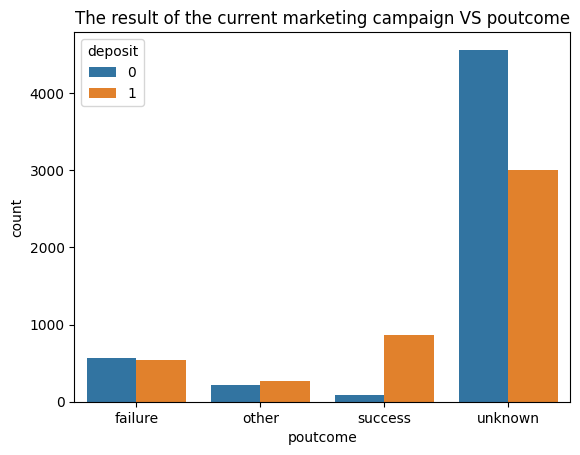

In [14]:
# Узнаем, для какого статуса предыдущей маркетинговой кампании успех в текущей превалирует над количеством неудач.
# Группируем данные по результату прошлой кампании и подсчитываем количество значений в каждой группе по признаку deposit
data = data.groupby('poutcome', as_index=False)['deposit'].value_counts()
display(data)

# Строим столбчатую диаграмму по полученным данным
fig = sns.barplot(data=data, x='poutcome', y = 'count', hue='deposit')
fig.set_title('The result of the current marketing campaign VS poutcome')
fig = plt.gcf()
plot_path = save_plot(fig, experiment_name="eda_marketing_campaign_VS_poutcome", plot_name="marketing_campaign_VS_poutcome");
print(f"График сохранён: {plot_path}")

>Выводы:

* Статус success предыдущей кампании — наиболее сильный предиктор успеха текущей: доля депозитов ≈91% (861 из 945).
* Статус other демонстрирует умеренную положительную связь: доля депозитов ≈55% (265 из 481).
* Статусы failure и unknown не являются индикаторами успеха: в failure доля депозитов ≈49% (547 из 1108), в unknown — ≈40% (3008 из 7570).
* Практический вывод: при таргетировании целесообразно приоритизировать клиентов с историей success, умеренно задействовать сегмент other; сегменты failure и unknown требуют иных стратегий привлечения.

,month,deposit,proportion
1,apr,no,0.381928
2,aug,no,0.559567
5,dec,no,0.096774
7,feb,no,0.455571
8,jan,no,0.608150
10,jul,no,0.589563
12,jun,no,0.548913
15,mar,no,0.101266
16,may,no,0.678517
18,nov,no,0.584615


График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_no_deposit_VS_month\plots\20261013_125122_no_deposit_VS_month.png


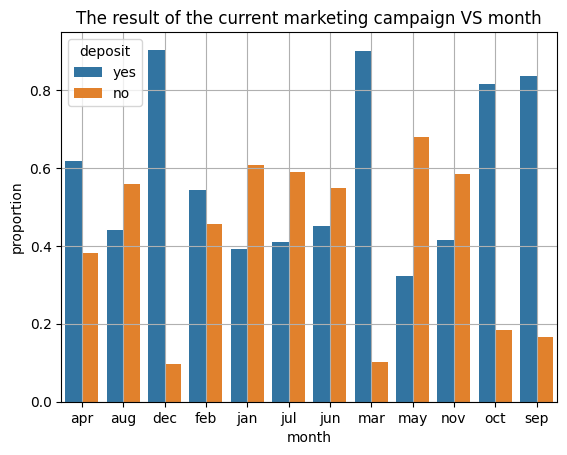

In [15]:
# узнаем, в каком месяце чаще всего отказывались от предложения открыть депозит
# Сгруппируем данные по признаку month и расчитаем доли значений по признаку deposit
data = cleaned_df.groupby('month', as_index=False)['deposit'].value_counts(normalize=True)
display(data[data['deposit']=='no'])
# Построим визуализацию
fig = sns.barplot(data=data, x='month', y='proportion', hue='deposit')
fig.set_title('The result of the current marketing campaign VS month')
fig.grid()
fig = plt.gcf()
plot_path = save_plot(fig, experiment_name="eda_no_deposit_VS_month", plot_name="no_deposit_VS_month");
print(f"График сохранён: {plot_path}")

> Выводы:

* Максимальная доля отказов зафиксирована в мае (≈70%).
* Высокие показатели отказов также отмечены в январе и июле (≈60%).
* Минимальная доля отказов — в декабре (≈10%).
* Практический вывод: в мае, январе и июле требуется усиление коммуникационной стратегии либо корректировка условий предложения; декабрь — наиболее благоприятный месяц для продвижения депозитов.

C:\Users\PC\AppData\Local\Temp\ipykernel_25244\722847661.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df.loc[:, 'age_group'] = pd.cut(


График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_Age_VS_deposit\plots\20261013_125122_Age_VS_deposit.png


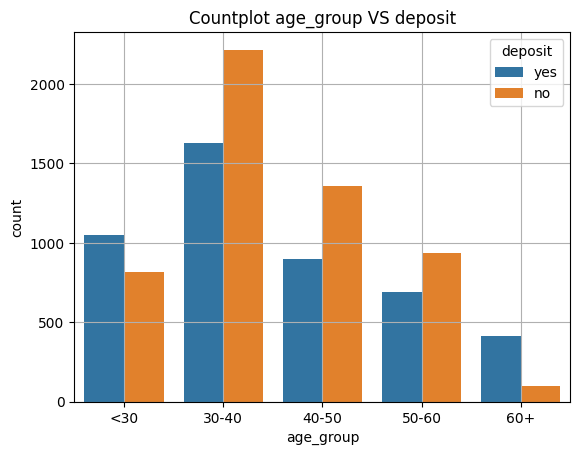

In [16]:
# создадим возрастные группы и определим, в каких группах более склонны открывать депозит, чем отказываться от предложения.
# Для разбиения на группы используем метод cut() библиотеки pandas
cleaned_df.loc[:, 'age_group'] = pd.cut(
    cleaned_df['age'],
    bins=[0, 30, 40, 50, 60, 120],
    labels=['<30', '30-40', '40-50', '50-60', '60+']
)
# Строим визуализацию
fig = sns.countplot(data=cleaned_df, x='age_group', hue='deposit')
fig.set_title('Countplot age_group VS deposit')
fig.grid()
fig = plt.gcf()
plot_path = save_plot(fig, experiment_name="eda_Age_VS_deposit", plot_name="Age_VS_deposit");
print(f"График сохранён: {plot_path}")
        

>Выводы:

* распределение числа клиентов по возрастным группам с разбивкой по факту открытия депозита (yes/no).
* Абсолютный максимум клиентов — в группе 30–40 (≈3900 чел.), при этом доля согласившихся — ≈42%.
* Наибольшая конверсия — в группе 60+ (≈80% yes), несмотря на минимальную численность сегмента (≈500 чел.).
* В группе <30 конверсия ≈55% при умеренном объеме (≈1900 чел.).
* Группы 40–50 и 50–60 демонстрируют сопоставимую конверсию (≈40–42%) при снижении численности с ростом возраста.
* сегмент 60+ — наиболее восприимчивый к предложению (80% конверсии); сегмент 30–40 — ключевой по объему, но с низкой конверсией (42%).

График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_marital_education\plots\20261013_125123_marital_education_vs_deposit.png


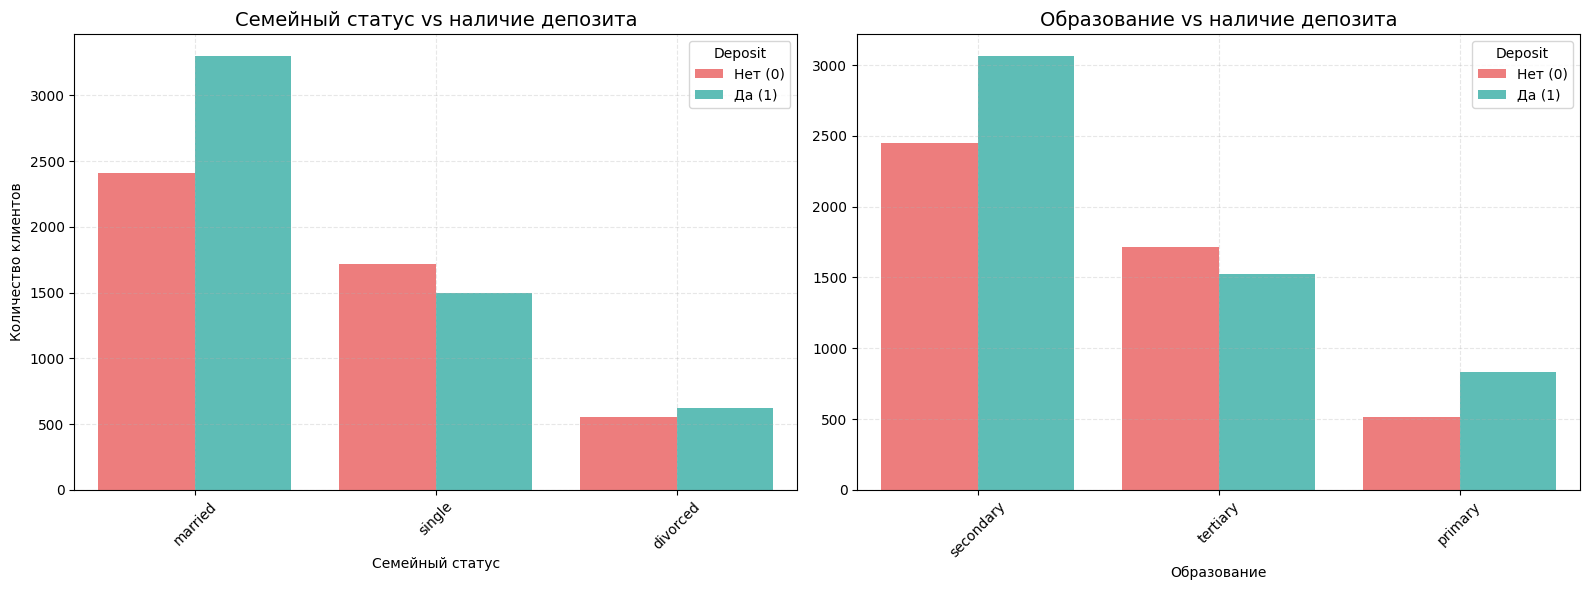

In [17]:
# Зависимость открытия или не открытия депозита от семейного положения и образования
fig, axes = plt.subplots(1, 2, figsize=(16, 6))  # 1 строка, 2 столбца

# График 1: marital vs deposit
sns.countplot(
    data=cleaned_df,
    x='marital',
    hue='deposit',
    palette=['#ff6b6b', '#4ecdc4'],
    ax=axes[0]
)
axes[0].set_title('Семейный статус vs наличие депозита', fontsize=14)
axes[0].set_xlabel('Семейный статус')
axes[0].set_ylabel('Количество клиентов')
axes[0].legend(title='Deposit', labels=['Нет (0)', 'Да (1)'])
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.3)

# График 2: education vs deposit
sns.countplot(
    data=cleaned_df,
    x='education',
    hue='deposit',
    palette=['#ff6b6b', '#4ecdc4'],
    ax=axes[1]
)
axes[1].set_title('Образование vs наличие депозита', fontsize=14)
axes[1].set_xlabel('Образование')
axes[1].set_ylabel('')  # убираем подпись оси Y у правого графика, чтобы не дублировать
axes[1].legend(title='Deposit', labels=['Нет (0)', 'Да (1)'])
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

plot_path = save_plot(fig, experiment_name="eda_marital_education", plot_name="marital_education_vs_deposit")

print(f"График сохранён: {plot_path}")

>Выводы:

* Семейный статус:
    * Группа married — наибольший объём клиентов (~5700) и высокая конверсия в депозит (≈55%).
    * Группа single — умеренный объём (~3300), конверсия ниже (≈46%).
    * Группа divorced — наименьший объём (~1100), конверсия ≈53%.
* Образование:
    * Группа secondary — максимальный объём (~5600), конверсия ≈55%.
    * Группа tertiary — объём ~3400, конверсия ≈46%.
    * Группа primary — наименьший объём (~1400), но самая высокая конверсия (≈67%).

Вывод:
* По семейному статусу: клиенты в браке — ключевой сегмент по объёму и конверсии; одинокие — наименее конверсионная группа.
* По образованию: клиенты со средним образованием — основной объём; клиенты с начальным образованием — наиболее восприимчивы к предложению (67% конверсии), несмотря на малую численность.

График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_job_VS_deposit\plots\20261013_125123_job_VS_deposit.png


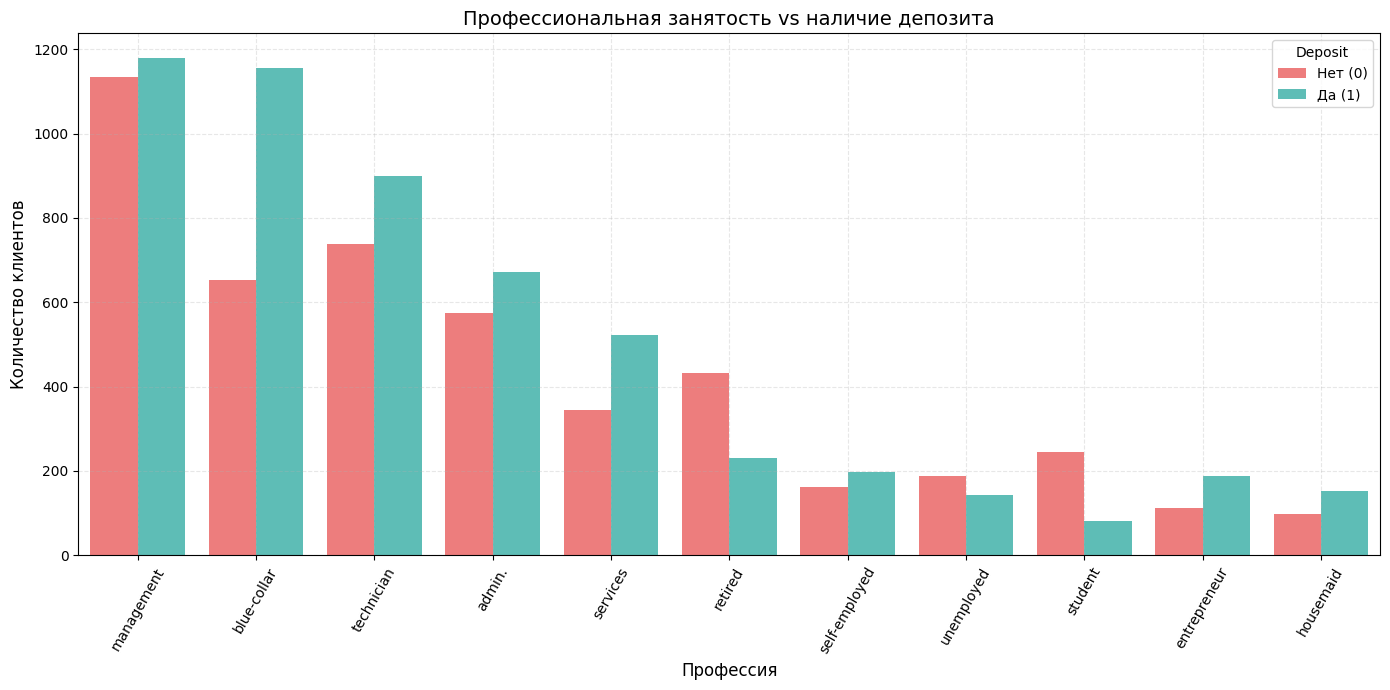

In [18]:
# 1. Считаем порядок категорий по частоте (чтобы самые частые были слева)
job_order = (
    cleaned_df['job']
    .value_counts()
    .index
    .tolist()
)

# 2. Строим график
fig, ax = plt.subplots(figsize=(14, 7))  # шире и выше — чтобы подписи не наезжали

sns.countplot(
    data=cleaned_df,
    x='job',
    hue='deposit',
    palette=['#ff6b6b', '#4ecdc4'],
    order=job_order,          # категории по убыванию частоты
    ax=ax
)

ax.set_title('Профессиональная занятость vs наличие депозита', fontsize=14)
ax.set_xlabel('Профессия', fontsize=12)
ax.set_ylabel('Количество клиентов', fontsize=12)
ax.legend(title='Deposit', labels=['Нет (0)', 'Да (1)'])

# Поворот подписей (правильно через ax.tick_params)
ax.tick_params(axis='x', rotation=60)
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

# Сохраняем именно fig
plot_path = save_plot(fig, experiment_name="eda_job_VS_deposit", plot_name="job_VS_deposit")

print(f"График сохранён: {plot_path}")

In [19]:
cleaned_df = cleaned_df.copy()
target_raw = cleaned_df['deposit'].astype(str).str.lower().str.strip()
mapping = {'yes': 1, 'no': 0}
cleaned_df['deposit'] = target_raw.map(mapping).fillna(0).astype('Int64')
print(f"Всего клиентов с депозитом: {cleaned_df['deposit'].sum()}")

Всего клиентов с депозитом: 4681


Всего клиентов с депозитом: 4681
Всего клиентов без депозита: 5423


'Количество клиентов с депозитом (deposit = 1)'

education,primary,secondary,tertiary
marital,,,
divorced,96,283,174
married,339,1289,784
single,82,879,755


'Количество клиентов без депозита (deposit = 0)'

education,primary,secondary,tertiary
marital,,,
divorced,91,370,163
married,641,1830,831
single,100,866,531


График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\eda_marital_education_heatmaps\plots\20261013_125124_marital_edu_heatmap.png


'Доля депозитов по комбинациям marital × education'

education,primary,secondary,tertiary
marital,,,
divorced,0.513,0.433,0.516
married,0.346,0.413,0.485
single,0.451,0.504,0.587


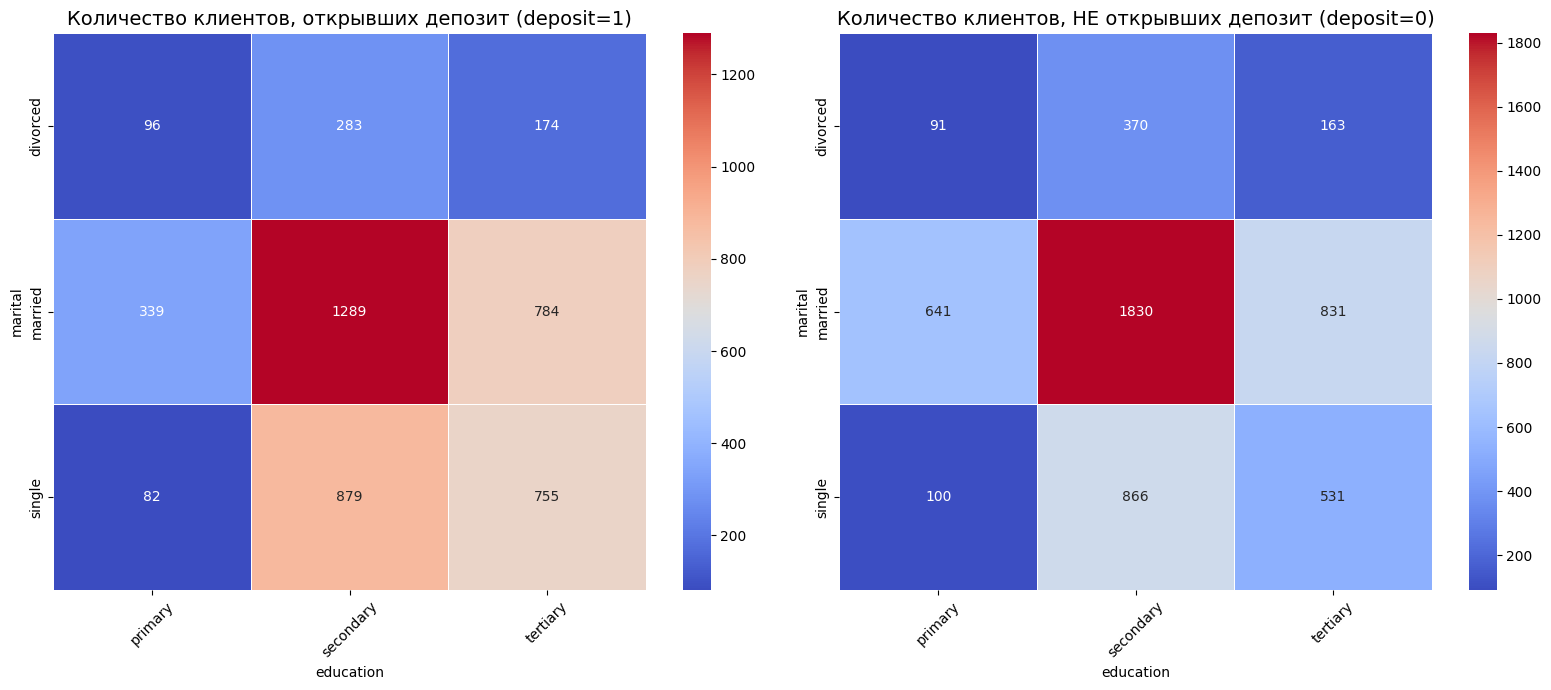

In [20]:
# постройте сводную таблицу, чтобы определить люди с каким образованием и семейным статусом наиболее многочисленны
# (если рассматривать тех, кто открыл депозит)

# 1. Фильтруем по статусу депозита
# ВАЖНО: Предполагаем, что 'deposit' уже числовой (0/1). Если нет — сделай map заранее.
df_yes = cleaned_df[cleaned_df['deposit'] == 1]
df_no  = cleaned_df[cleaned_df['deposit'] == 0]

print(f"Всего клиентов с депозитом: {len(df_yes)}")
print(f"Всего клиентов без депозита: {len(df_no)}")

# Проверка: если кого-то нет, дальше не строим heatmap для этой группы
if len(df_yes) == 0 or len(df_no) == 0:
    print("⚠️ Недостаточно данных для построения обеих тепловых карт. Строим только сводную таблицу долей.")
    # Сразу переходим к таблице долей (она работает даже при малом числе строк)
else:
    # 2. Сводные таблицы: marital × education (количество людей)
    ct_yes = pd.crosstab(df_yes['marital'], df_yes['education']).fillna(0).astype(int)
    ct_no  = pd.crosstab(df_no['marital'],  df_no['education']).fillna(0).astype(int)

    display('Количество клиентов с депозитом (deposit = 1)', ct_yes)
    display('Количество клиентов без депозита (deposit = 0)', ct_no)

    # 3. Тепловые карты на одной фигуре (только если данные есть)
    fig, ax = plt.subplots(ncols=2, figsize=(16, 7))

    sns.heatmap(ct_yes, annot=True, fmt='d', cmap='coolwarm', linewidths=.5, ax=ax[0])
    ax[0].set_title('Количество клиентов, открывших депозит (deposit=1)', fontsize=14)
    ax[0].tick_params(axis='x', rotation=45)

    sns.heatmap(ct_no, annot=True, fmt='d', cmap='coolwarm', linewidths=.5, ax=ax[1])
    ax[1].set_title('Количество клиентов, НЕ открывших депозит (deposit=0)', fontsize=14)
    ax[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()

    plot_path = save_plot(fig, experiment_name="eda_marital_education_heatmaps", plot_name="marital_edu_heatmap")
  
    print(f"График сохранён: {plot_path}")

# 4. ГЛАВНАЯ ТАБЛИЦА ДЛЯ ОТЧЁТА: доля депозитов по комбинациям
# Это работает даже если строк мало, потому что считает mean по всему датасету
overall_cross = pd.crosstab(
    cleaned_df['marital'],
    cleaned_df['education'],
    values=cleaned_df['deposit'],
    aggfunc='mean'
).fillna(0).round(3)

display('Доля депозитов по комбинациям marital × education', overall_cross)

In [21]:
# Создаем новые признаки на основе вышеперечисленных иссследований
df_feat = create_marketing_features(cleaned_df)

In [22]:
# Создаём признак marital_edu_target

# Создаём ключ
df_feat.loc[:, 'marital_edu_key'] = (
    df_feat['marital'].astype(str) + '_' + df_feat['education'].astype(str)
)

# Словарь: ключ -> доля конверсии
mapping_dict = overall_cross.stack().to_dict()

# Применяем
df_feat.loc[:, 'marital_edu_target'] = df_feat['marital_edu_key'].map(mapping_dict)

# Заполняем редкие комбинации (которых не было в таблице) глобальным средним
global_mean = df_feat['deposit'].mean()
df_feat.loc[:, 'marital_edu_target'] = df_feat['marital_edu_target'].fillna(global_mean)

# Удаляем вспомогательный ключ (если не нужен дальше)
df_feat = df_feat.drop(columns=['marital_edu_key'])

print("Новый признак создан. Примеры:")
display(df_feat[['marital', 'education', 'marital_edu_target']].head(10))

Новый признак создан. Примеры:


,marital,education,marital_edu_target
0,married,secondary,0.463282
1,married,secondary,0.463282
2,married,secondary,0.463282
3,married,secondary,0.463282
4,married,tertiary,0.463282
5,single,tertiary,0.463282
6,married,tertiary,0.463282
7,divorced,secondary,0.463282
8,married,secondary,0.463282
9,single,secondary,0.463282


---

### 3.0 Сплит

In [23]:
X = df_feat.drop(columns=['deposit'])
y = df_feat['deposit']

---

### 3.1 Baseline: DecisionTreeClassifier

In [24]:
# --- SPLIT СО СТРАТИФИКАЦИЕЙ ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# АВТОМАТИЧЕСКИ ОПРЕДЕЛЯЕМ ТИПЫ КОЛОНОК
# Берём типы колонок из X_train
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

print(f"Числовые колонки ({len(numeric_cols)}): {numeric_cols[:5]}...")
print(f"Категориальные колонки ({len(categorical_cols)}): {categorical_cols[:5]}...")

if len(numeric_cols) == 0 and len(categorical_cols) == 0:
    raise ValueError("В X_train не найдено ни числовых, ни категориальных колонок!")

# --- 2. СОЗДАЁМ ПРЕПРОЦЕССОР ---
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# --- 3. МОДЕЛЬ ---
tree_clf = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    random_state=42
)

tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', tree_clf)
])

# --- 4. CROSS-VALIDATION ---
cv_scores = cross_val_score(tree_pipeline, X_train, y_train, cv=5, scoring='roc_auc')
print(f"\n✅ DecisionTree — CV ROC-AUC на train: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

# --- 5. ОБУЧЕНИЕ И ОЦЕНКА НА ТЕСТЕ ---
tree_pipeline.fit(X_train, y_train)

# --- НАДЁЖНАЯ ПРОВЕРКА КЛАССОВ ---
unique_test, counts_test = np.unique(y_test, return_counts=True)
print(f"\n🔍 Проверка классов в y_test: {dict(zip(unique_test, counts_test))}")

if 1 not in unique_test or counts_test[unique_test == 1][0] == 0:
    raise ValueError("❌ В тестовой выборке НЕТ примеров класса 1! Стратификация не сработала.")

# --- ПРЕДСКАЗАНИЯ И ROC-AUC ---
y_pred_proba = tree_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

test_auc = roc_auc_score(y_test, y_pred_proba)
print(f"✅ Test ROC-AUC: {test_auc:.3f}")

# --- УМНЫЙ ПОИСК КЛЮЧА ДЛЯ КЛАССА 1 ---
report = classification_report(y_test, y_pred, digits=3, output_dict=True)

target_key = None
for key in report.keys():
    try:
        if float(key) == 1.0:
            target_key = key
            break
    except (ValueError, TypeError):
        continue

if target_key is None:
    raise ValueError("❌ Не удалось найти ключ для класса 1 в classification_report. Проверьте y_test и y_pred.")

print(f"✅ Использован ключ для класса депозита: '{target_key}'")

# --- СБОР МЕТРИК---
metrics_dict = {
    "roc_auc": test_auc,
    "accuracy": report["accuracy"],
    "precision": float(report[target_key]["precision"]),
    "recall": float(report[target_key]["recall"]),
    "f1": float(report[target_key]["f1-score"]),
    "support_1": int(report[target_key]["support"]),
}

print("\n📊 Classification report:")
print(classification_report(y_test, y_pred, digits=3))

# --- ПАРАМЕТРЫ И ФИЧИ ---
model_params = {
    "model_type": "DecisionTreeClassifier",
    "max_depth": tree_clf.max_depth,
    "min_samples_split": tree_clf.min_samples_split,
    "random_state": 42,
}
feature_list = X_train.columns.tolist()

# --- ЛОГГЕР ---
log_result = log_experiment(
    name="deposit_prediction_v1_decision_tree",
    params=model_params,
    metrics=metrics_dict,
    features=feature_list,
    random_state=42,
    baseline_roc_auc=0.55,
)

print("\n📜 Эксперимент залогирован!")

Числовые колонки (9): ['age', 'balance', 'day', 'duration', 'campaign']...
Категориальные колонки (11): ['job', 'marital', 'education', 'default', 'housing']...

✅ DecisionTree — CV ROC-AUC на train: 0.868 ± 0.007

🔍 Проверка классов в y_test: {0: 1085, 1: 936}
✅ Test ROC-AUC: 0.870
✅ Использован ключ для класса депозита: '1.0'

📊 Classification report:
              precision    recall  f1-score   support

         0.0      0.785     0.850     0.816      1085
         1.0      0.808     0.731     0.767       936

    accuracy                          0.795      2021
   macro avg      0.796     0.790     0.792      2021
weighted avg      0.796     0.795     0.794      2021


📜 Эксперимент залогирован!


### 3.2 DecisionTreeClassifier  с подбором гиперпараметров через GridSearchCV

In [25]:
# --- 1. Препроцессор ---
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# --- 2. Базовый пайплайн (препроцессор + модель) ---
base_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='entropy', random_state=42))
])

# --- 3. Сетка параметров ---
# ВАЖНО: обращаемся к модели внутри пайплайна через имя 'classifier'
param_grid = {
    'classifier__min_samples_split': [2, 5, 7, 10],
    'classifier__max_depth': [3, 5, 7]
}

# --- 4. GridSearchCV ---
grid_search = GridSearchCV(
    estimator=base_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Запускаем подбор гиперпараметров (это может занять пару минут)...")
grid_search.fit(X_train, y_train)

print(f"\n✅ Лучшая комбинация гиперпараметров: {grid_search.best_params_}")
print(f"✅ Средний F1 на кросс‑валидации: {grid_search.best_score_:.3f}")

# --- 5. Финальная оценка на тесте ---
y_pred = grid_search.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
y_pred_proba = grid_search.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_pred_proba)

print(f"📉 F1 на тестовой выборке: {test_f1:.3f}")
print(f"📊 ROC‑AUC на тесте: {test_auc:.3f}")

Запускаем подбор гиперпараметров (это может занять пару минут)...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

✅ Лучшая комбинация гиперпараметров: {'classifier__max_depth': 7, 'classifier__min_samples_split': 10}
✅ Средний F1 на кросс‑валидации: 0.806
📉 F1 на тестовой выборке: 0.793
📊 ROC‑AUC на тесте: 0.881


---

### 3.3 LogisticRegression

In [26]:
# --- 1. МОДЕЛЬ: ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ ---

from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(
    penalty='l2',          
    C=1.0,                 
    solver='lbfgs',        
    max_iter=1000,         
    class_weight='balanced',  
    random_state=42
)

log_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', log_reg)
])

# --- 2. CROSS-VALIDATION ---
cv_scores = cross_val_score(log_pipeline, X_train, y_train, cv=5, scoring='roc_auc')
print(f"\n✅ Logistic Regression — CV ROC-AUC на train: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

# --- 3. ОБУЧЕНИЕ И ОЦЕНКА НА ТЕСТЕ ---
log_pipeline.fit(X_train, y_train)

y_pred_proba = log_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)

test_auc = roc_auc_score(y_test, y_pred_proba)
print(f"✅ Test ROC-AUC: {test_auc:.3f}")

# Умный поиск ключа для класса 1
report = classification_report(y_test, y_pred, digits=3, output_dict=True)
target_key = None
for key in report.keys():
    try:
        if float(key) == 1.0:
            target_key = key
            break
    except (ValueError, TypeError):
        continue

if target_key is None:
    raise ValueError("❌ Не удалось найти ключ для класса 1 в classification_report.")

print(f"✅ Использован ключ для класса депозита: '{target_key}'")

metrics_dict = {
    "roc_auc": test_auc,
    "accuracy": report["accuracy"],
    "precision": float(report[target_key]["precision"]),
    "recall": float(report[target_key]["recall"]),
    "f1": float(report[target_key]["f1-score"]),
    "support_1": int(report[target_key]["support"]),
}

# --- 4. ПАРАМЕТРЫ МОДЕЛИ ---
model_params = {
    "model_type": "LogisticRegression",
    "penalty": log_reg.penalty,
    "C": log_reg.C,
    "solver": log_reg.solver,
    "max_iter": log_reg.max_iter,
    "class_weight": log_reg.class_weight,
    "random_state": log_reg.random_state,
}

feature_list = X_train.columns.tolist()

# --- 5. ЛОГГИРОВАНИЕ ЭКСПЕРИМЕНТА (с метриками И топ‑признаками) ---
log_result = log_experiment(
    name="deposit_prediction_v1_logreg",
    params=model_params,
    metrics=metrics_dict,
    features=feature_list,
    random_state=42,
    baseline_roc_auc=0.55
)

print("\n📜 Эксперимент залогирован!")

print("\n📊 Classification report:")
print(classification_report(y_test, y_pred, digits=3))


✅ Logistic Regression — CV ROC-AUC на train: 0.909 ± 0.006
✅ Test ROC-AUC: 0.907
✅ Использован ключ для класса депозита: '1.0'

📜 Эксперимент залогирован!

📊 Classification report:
              precision    recall  f1-score   support

         0.0      0.838     0.851     0.844      1085
         1.0      0.824     0.809     0.816       936

    accuracy                          0.831      2021
   macro avg      0.831     0.830     0.830      2021
weighted avg      0.831     0.831     0.831      2021



---

### 3.4 RandomForestClassifier

In [27]:
# --- 1. Препроцессор---
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())  # для RF скейлер не обязателен, но не повредит
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# --- 2. Базовый пайплайн (препроцессор + Random Forest) ---
base_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# --- 3. Сетка параметров (GridSearch) ---
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [5, 10, 15],
    'classifier__min_samples_leaf': [1, 5, 10],
    'classifier__criterion': ['gini', 'entropy']
}

# --- 4. GridSearchCV ---
grid_search_rf = GridSearchCV(
    estimator=base_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Запускаем подбор гиперпараметров для Random Forest (это может занять 3–7 минут)...")
grid_search_rf.fit(X_train, y_train)

print(f"\n✅ Лучшая комбинация гиперпараметров: {grid_search_rf.best_params_}")
print(f"✅ Средний F1 на кросс‑валидации: {grid_search_rf.best_score_:.3f}")

# --- 5. Финальная оценка на тесте ---
y_pred = grid_search_rf.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
y_pred_proba = grid_search_rf.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_pred_proba)

print(f"📉 F1 на тестовой выборке: {test_f1:.3f}")
print(f"📊 ROC‑AUC на тесте: {test_auc:.3f}")

Запускаем подбор гиперпараметров для Random Forest (это может занять 3–7 минут)...
Fitting 5 folds for each of 54 candidates, totalling 270 fits

✅ Лучшая комбинация гиперпараметров: {'classifier__criterion': 'entropy', 'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
✅ Средний F1 на кросс‑валидации: 0.843
📉 F1 на тестовой выборке: 0.836
📊 ROC‑AUC на тесте: 0.914


In [28]:
# Собираем параметры модели (убираем префикс classifier__ для читаемости в логе)
clean_params = {k.replace("classifier__", ""): v for k, v in grid_search_rf.best_params_.items()}

model_params = {
    "model_type": "RandomForestClassifier_in_Pipeline",
    "best_params": clean_params,
    "cv_folds": 5,
    "scoring": "f1",
    "random_state": 42,
    "n_features": len(X_train.columns)
}

# Метрики
metrics_dict = {
    "best_cv_f1": float(grid_search_rf.best_score_),
    "test_f1": float(test_f1),
    "test_roc_auc": float(test_auc),
    "accuracy": float(metrics.accuracy_score(y_test, y_pred)),
    "precision": float(report[target_key]["precision"]),
    "recall": float(report[target_key]["recall"])
}

# Логируем
log_result = log_experiment(
    name="deposit_prediction_rf_gridsearch_final",
    params=model_params,
    metrics=metrics_dict,
    features=X_train.columns.tolist(),
    random_state=42,
    baseline_roc_auc=0.914
)

print("\n📜 Эксперимент полностью залогирован!")


📜 Эксперимент полностью залогирован!


---

### 3.5 GradientBoostingClassifier

In [29]:
# --- 1. Препроцессор---
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# --- 2. Базовый пайплайн (препроцессор + Gradient Boosting) ---
base_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

# --- 3. Сетка параметров (GridSearch) ---
param_grid = {
    'classifier__learning_rate': [0.01, 0.05, 0.1],
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5, 7],
    'classifier__min_samples_leaf': [1, 5, 10]
}

# --- 4. GridSearchCV ---
grid_search_gb = GridSearchCV(
    estimator=base_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Запускаем подбор гиперпараметров для Gradient Boosting (это может занять 5–12 минут)...")
grid_search_gb.fit(X_train, y_train)

print(f"\n✅ Лучшая комбинация гиперпараметров: {grid_search_gb.best_params_}")
print(f"✅ Средний F1 на кросс‑валидации: {grid_search_gb.best_score_:.3f}")

# --- 5. Финальная оценка на тесте ---
y_pred = grid_search_gb.predict(X_test)
y_pred_proba = grid_search_gb.predict_proba(X_test)[:, 1]

test_f1 = f1_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_pred_proba)
test_acc = accuracy_score(y_test, y_pred)

print(f"📉 F1 на тестовой выборке: {test_f1:.3f}")
print(f"📊 ROC‑AUC на тесте: {test_auc:.3f}")
print(f"📈 Accuracy на тесте: {test_acc:.3f}")

Запускаем подбор гиперпараметров для Gradient Boosting (это может занять 5–12 минут)...
Fitting 5 folds for each of 81 candidates, totalling 405 fits

✅ Лучшая комбинация гиперпараметров: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 300}
✅ Средний F1 на кросс‑валидации: 0.857
📉 F1 на тестовой выборке: 0.845
📊 ROC‑AUC на тесте: 0.923
📈 Accuracy на тесте: 0.853


In [30]:
# Подготовка параметров (убираем префикс classifier__)
clean_params = {k.replace("classifier__", ""): v for k, v in grid_search_gb.best_params_.items()}

model_params = {
    "model_type": "GradientBoostingClassifier_in_Pipeline",
    "best_params": clean_params,
    "cv_folds": 5,
    "scoring": "f1",
    "random_state": 42,
    "n_features": len(X_train.columns)
}

# Метрики
metrics_dict = {
    "best_cv_f1": float(grid_search_gb.best_score_),
    "test_f1": float(test_f1),
    "test_roc_auc": float(test_auc),
    "test_accuracy": float(test_acc)
}

# Логирование эксперимента
log_result = log_experiment(
    name="deposit_prediction_gb_gridsearch_final",
    params=model_params,
    metrics=metrics_dict,
    features=X_train.columns.tolist(),
    random_state=42,
    baseline_roc_auc=0.923
)
print("\n📜 Эксперимент с Gradient Boosting полностью залогирован!")


📜 Эксперимент с Gradient Boosting полностью залогирован!


---

### 3.6 StackingClassifier

In [31]:
# --- 1. Препроцессор---
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# --- 2. Базовые модели (в пайплайнах) ---
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=7, min_samples_split=10, random_state=42))
])

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='lbfgs',
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        learning_rate=0.05,
        max_depth=5,
        min_samples_leaf=10,
        n_estimators=300,
        random_state=42
    ))
])

# --- 3. Мета‑модель ---
meta_clf = LogisticRegression(
    penalty='l2',
    C=1.0,
    solver='lbfgs',
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

# --- 4. StackingClassifier ---
stacking_clf = StackingClassifier(
    estimators=[
        ('dt', dt_pipeline),
        ('lr', lr_pipeline),
        ('gb', gb_pipeline)
    ],
    final_estimator=meta_clf,
    cv=5,                # кросс‑валидация для получения out‑of‑fold прогнозов базовых моделей
    stack_method='predict_proba',  # используем вероятности (лучше для ROC‑AUC)
    n_jobs=-1
)

print("Запускаем обучение стекинга (это может занять 7–15 минут)...")
stacking_clf.fit(X_train, y_train)

# --- 5. Оценка на тесте ---
y_pred = stacking_clf.predict(X_test)
y_pred_proba = stacking_clf.predict_proba(X_test)[:, 1]

test_f1 = f1_score(y_test, y_pred)
test_auc = roc_auc_score(y_test, y_pred_proba)
test_acc = accuracy_score(y_test, y_pred)

print(f"\n✅ F1 на тестовой выборке (стекинг): {test_f1:.3f}")
print(f"✅ ROC‑AUC на тесте (стекинг): {test_auc:.3f}")
print(f"✅ Accuracy на тесте (стекинг): {test_acc:.3f}")

Запускаем обучение стекинга (это может занять 7–15 минут)...

✅ F1 на тестовой выборке (стекинг): 0.844
✅ ROC‑AUC на тесте (стекинг): 0.924
✅ Accuracy на тесте (стекинг): 0.852


---

🔥 Топ‑15 признаков (Gradient Boosting):
         feature  importance
        duration    0.446788
poutcome_success    0.104972
 contact_unknown    0.069289
           pdays    0.043995
             day    0.037080
             age    0.028948
       month_mar    0.027652
      housing_no    0.022945
     housing_yes    0.021545
       month_jun    0.018689
       month_oct    0.018376
     balance_log    0.016593
       month_apr    0.015495
         balance    0.011448
       month_sep    0.010225


C:\Users\PC\AppData\Local\Temp\ipykernel_25244\347657302.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_15, x='importance', y='feature', palette='viridis')


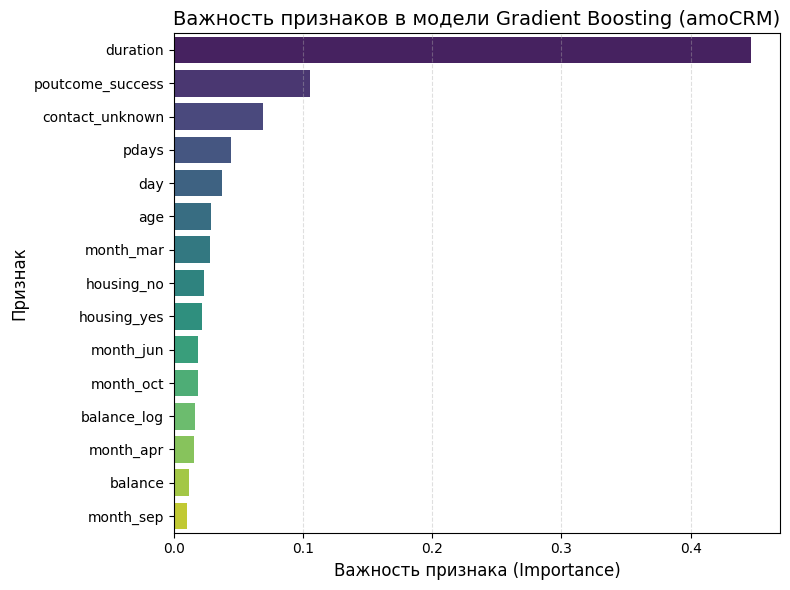

График сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\feature_importances\plots\20261013_125652_Top-15_featue_importances.png


In [32]:
# 1. Достаём обученную модель (пайплайн с препроцессором + GB)
best_gb_model = grid_search_gb.best_estimator_  

# 2. Восстанавливаем имена признаков (после OneHot)
ohe = best_gb_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_feature_names = ohe.get_feature_names_out(categorical_cols)
feature_names = pd.Index(numeric_cols).append(pd.Index(cat_feature_names))

# 3. Важности признаков
importances = best_gb_model.named_steps['classifier'].feature_importances_

# 4. Топ‑15 самых важных
feat_imp = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

top_15 = feat_imp.head(15)
print("🔥 Топ‑15 признаков (Gradient Boosting):")
print(top_15.to_string(index=False))

# 5. Визуализация
plt.figure(figsize=(8, 6))
ax = sns.barplot(data=top_15, x='importance', y='feature', palette='viridis')

ax.set_xlabel('Важность признака (Importance)', fontsize=12)
ax.set_ylabel('Признак', fontsize=12)
ax.set_title('Важность признаков в модели Gradient Boosting (amoCRM)', fontsize=14)
ax.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
plot_path = save_plot(fig, experiment_name="feature_importances", plot_name="Top-15_featue_importances")
  
print(f"График сохранён: {plot_path}")

---

### 3.7 препроцессор → RFE → классификатор

In [33]:
# 1. Препроцессор
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

# 2. Модель GB с теми же параметрами
gb_clf = GradientBoostingClassifier(
    learning_rate=0.05,
    max_depth=5,
    min_samples_leaf=10,
    n_estimators=300,
    random_state=42
)

# 3. RFE
rfe = RFE(estimator=gb_clf, n_features_to_select=3, step=1)

# 4. Пайплайн: препроцессор → RFE → классификатор
rfe_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rfe', rfe),
    ('classifier', gb_clf)
])

print("🚀 Обучаем пайплайн с RFE (это может занять 5–10 минут)...")
rfe_pipeline.fit(X_train, y_train)

# 5. Получаем 3 лучших признака
rfe_selector = rfe_pipeline.named_steps['rfe']
# Чтобы получить имена, нужно применить препроцессор отдельно и взять имена колонок
preprocessed_cols = rfe_pipeline.named_steps['preprocessor'].get_feature_names_out()
best_3_rfe = preprocessed_cols[rfe_selector.support_]

print("\n🔥 Топ‑3 признака по RFE:")
for i, feat in enumerate(best_3_rfe, 1):
    print(f"{i}. {feat}")

🚀 Обучаем пайплайн с RFE (это может занять 5–10 минут)...

🔥 Топ‑3 признака по RFE:
1. num__duration
2. cat__contact_unknown
3. cat__poutcome_success


---

### 3.8 RandomForest + Optuna

In [34]:
# Функция цели для Optuna
def optuna_rf(trial):
    # Пространство поиска гиперпараметров
    n_estimators = trial.suggest_int('n_estimators', 100, 200)          # количество деревьев
    max_depth = trial.suggest_int('max_depth', 10, 30)                 # глубина дерева
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 2, 10)    # минимум объектов в листе
    
    # Модель
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=42,
        n_jobs=-1
    )
    
    # Пайплайн: препроцессор + модель
    rf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Кросс‑валидация
    cv_scores = cross_val_score(
        rf_pipeline, X_train, y_train,
        cv=5,
        scoring=make_scorer(f1_score),
        n_jobs=-1
    )
    
    return cv_scores.mean()

# Запуск оптимизации
study = optuna.create_study(direction='maximize')
print("🚀 Запускаем Optuna для RandomForest (это займёт 5–12 минут)...")
study.optimize(optuna_rf, n_trials=40, timeout=900)  

# Лучшие параметры
best_params = study.best_params
print("\n🏆 Лучшие параметры (RandomForest + Optuna):")
print(best_params)

# Обучаем финальную модель с лучшими параметрами
best_rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(**best_params, random_state=42, n_jobs=-1))
])
best_rf_model.fit(X_train, y_train)

# Оценка на тесте
y_pred_rf = best_rf_model.predict(X_test)
y_pred_proba_rf = best_rf_model.predict_proba(X_test)[:, 1]

from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
test_f1_rf = f1_score(y_test, y_pred_rf)
test_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)
test_acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"\n✅ Test F1 (RF + Optuna): {test_f1_rf:.3f}")
print(f"✅ Test ROC‑AUC (RF + Optuna): {test_auc_rf:.3f}")
print(f"✅ Test Accuracy (RF + Optuna): {test_acc_rf:.3f}")

[I 2026-10-13 13:07:43,731] A new study created in memory with name: no-name-439aec57-58c7-45eb-adb0-cca915b0c9ee


🚀 Запускаем Optuna для RandomForest (это займёт 5–12 минут)...


[I 2026-10-13 13:07:46,477] Trial 0 finished with value: 0.8372886401099466 and parameters: {'n_estimators': 100, 'max_depth': 21, 'min_samples_leaf': 5}. Best is trial 0 with value: 0.8372886401099466.
[I 2026-10-13 13:07:49,082] Trial 1 finished with value: 0.8403246954182471 and parameters: {'n_estimators': 111, 'max_depth': 17, 'min_samples_leaf': 2}. Best is trial 1 with value: 0.8403246954182471.
[I 2026-10-13 13:07:51,868] Trial 2 finished with value: 0.8386026339943993 and parameters: {'n_estimators': 131, 'max_depth': 25, 'min_samples_leaf': 4}. Best is trial 1 with value: 0.8403246954182471.
[I 2026-10-13 13:07:53,963] Trial 3 finished with value: 0.8358598914176076 and parameters: {'n_estimators': 106, 'max_depth': 21, 'min_samples_leaf': 7}. Best is trial 1 with value: 0.8403246954182471.
[I 2026-10-13 13:07:55,945] Trial 4 finished with value: 0.8382604976595192 and parameters: {'n_estimators': 184, 'max_depth': 22, 'min_samples_leaf': 6}. Best is trial 1 with value: 0.840


🏆 Лучшие параметры (RandomForest + Optuna):
{'n_estimators': 200, 'max_depth': 27, 'min_samples_leaf': 2}

✅ Test F1 (RF + Optuna): 0.840
✅ Test ROC‑AUC (RF + Optuna): 0.916
✅ Test Accuracy (RF + Optuna): 0.848


In [35]:
# 1. Определяем, где мы сейчас (папка с ноутбуком)
current_dir = os.getcwd()
print(f"📂 Текущая папка (где лежит ноутбук): {current_dir}")

# 2. Поднимаемся на уровень выше, чтобы попасть в корень проекта (Project-4_Clean)
# Если ты запускаешь из notebooks/, то parent_dir будет корнем
parent_dir = os.path.dirname(current_dir)
print(f"📂 Корневая папка проекта: {parent_dir}")

# 3. Формируем путь к папке models в корне
MODELS_DIR_NAME = "models"
models_path = os.path.join(parent_dir, MODELS_DIR_NAME)

# Создаём папку, если её нет
os.makedirs(models_path, exist_ok=True)
print(f"✅ Папка для моделей: {models_path}")

# 4. Имена файлов
model_filename = "rf_optuna_final_v1.pkl"
log_filename = "rf_optuna_log_v1.json"

model_path = os.path.join(models_path, model_filename)
log_path = os.path.join(models_path, log_filename)

# 5. Сохраняем пайплайн
joblib.dump(best_rf_model, model_path)
print(f"💾 Модель сохранена: {model_path}")

# 6. Формируем и сохраняем JSON-отчёт
log_report = {
    "experiment_name": "deposit_prediction_rf_optuna",
    "timestamp": datetime.now().isoformat(),
    "model_type": "RandomForestClassifier_with_Optuna",
    "data_source": "amoCRM_deals_14524_9years",
    "target": "deposit_flag",
    "train_size": len(X_train),
    "test_size": len(X_test),
    "features_count": len(X_train.columns),
    "optuna_settings": {
        "direction": "maximize",
        "metric": "f1",
        "n_trials": 40,
        "timeout_seconds": 900
    },
    "best_params": best_params,
    "metrics": {
        "best_cv_f1": float(study.best_value),
        "test_f1": float(test_f1_rf),
        "test_roc_auc": float(test_auc_rf),
        "test_accuracy": float(test_acc_rf)
    },
    "artifact_path": model_path,
    "notes": "Модель сохранена в корневую папку models/ для чистоты структуры проекта."
}

with open(log_path, "w", encoding="utf-8") as f:
    json.dump(log_report, f, indent=2, ensure_ascii=False)
print(f"📝 Отчёт сохранён: {log_path}")

📂 Текущая папка (где лежит ноутбук): c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\notebooks
📂 Корневая папка проекта: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean
✅ Папка для моделей: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\models
💾 Модель сохранена: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\models\rf_optuna_final_v1.pkl
📝 Отчёт сохранён: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\models\rf_optuna_log_v1.json


In [36]:
# 1. Формируем правильный путь в папку experiments
current_dir = os.getcwd()
root_dir = os.path.dirname(current_dir)
experiments_dir = os.path.join(root_dir, "experiments")
os.makedirs(experiments_dir, exist_ok=True)
summary_path = os.path.join(experiments_dir, "summary.csv")

# 2. Готовим данные для строки
new_row = {
    "experiment_name": "deposit_prediction_rf_optuna_v1",
    "timestamp": pd.Timestamp.now().isoformat(),
    "model_type": "RandomForestClassifier",
    "accuracy": None,  
    "precision": None,
    "recall": None,
    "f1": float(study.best_value),          
    "roc_auc": float(test_auc_rf),      
    "baseline_roc_auc": None,
    "num_features": None,
    "warning_needed": False,
    "artifact_path": "models/rf_optuna_final_v1.pkl",
    "log_path": "models/rf_optuna_log_v1.json",  
    "tuning_method": "Optuna (TPE)",
    "trials": 40,
    "n_estimators": best_params.get("n_estimators"),  
    "max_depth": best_params.get("max_depth"),
    "min_samples_leaf": best_params.get("min_samples_leaf"),
    "notes": "min_samples_leaf=2 сохраняет редкие VIP-сегменты"
}

# 3. Читаем старый CSV и добавляем строку
if os.path.exists(summary_path):
    df = pd.read_csv(summary_path)
    df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
else:
    df = pd.DataFrame([new_row])

# 4. Сохраняем обратно
df.to_csv(summary_path, index=False)
print(f"✅ Чистый CSV сохранён в: {summary_path}")


✅ Чистый CSV сохранён в: c:\Users\PC\IDE\sf_data_science\Projects\Project-4_Clean\experiments\summary.csv


---

# Анализ важности признаков и упрощение модели

In [37]:
# 1. Достаём лучший пайплайн из GridSearch
best_pipeline = grid_search_rf.best_estimator_

# 2. Находим шаг с моделью (RandomForest), у которой есть feature_importances_
rf_step_name = None
for name, step in best_pipeline.named_steps.items():
    if hasattr(step, 'feature_importances_'):
        rf_step_name = name
        break

if rf_step_name is None:
    raise ValueError("Не найдена модель с feature_importances_ внутри пайплайна")

print(f"Модель найдена в шаге: '{rf_step_name}'")

# 3. Достаём саму модель и её важность
best_rf_model = best_pipeline.named_steps[rf_step_name]
importances = best_rf_model.feature_importances_

# 4. САМОЕ ВАЖНОЕ: Получаем имена колонок ПОСЛЕ препроцессинга
# Ищем шаг с ColumnTransformer (обычно называется 'preprocess' или 'num/cat')
preprocessor_step = None
for name, step in best_pipeline.named_steps.items():
    if hasattr(step, 'get_feature_names_out'):
        preprocessor_step = step
        break

if preprocessor_step is not None:
    # Это даст правильные имена (включая закодированные категории)
    feature_names = preprocessor_step.get_feature_names_out()
else:
    # Если препроцессора нет вообще, тогда можно брать исходные колонки
    feature_names = X_train.columns

# 5. Строим таблицу ТОЛЬКО если длины совпадают
if len(importances) == len(feature_names):
    feat_df = pd.DataFrame({
        'feature': feature_names,
        'importance': importances
    }).sort_values(by='importance', ascending=False)

    top_n = 15
    top_features = feat_df.head(top_n)['feature'].tolist()

    print(f"\nТоп-{top_n} самых важных признаков:")
    display(feat_df.head(top_n))
    
    # Сохраняем список, чтобы использовать в следующей ячейке
    # В Jupyter переменная top_features будет доступна дальше
else:
    print("ОШИБКА: Длины массивов не совпали. Проверь пайплайн.")

Модель найдена в шаге: 'classifier'

Топ-15 самых важных признаков:


,feature,importance
3,num__duration,0.324177
1,num__balance,0.049014
7,num__balance_log,0.045827
0,num__age,0.044652
2,num__day,0.042903
49,cat__poutcome_success,0.039416
5,num__pdays,0.033210
4,num__campaign,0.025863
6,num__previous,0.024414
34,cat__contact_unknown,0.022887


In [38]:
# Превращаем закодированные имена (num__duration, cat__poutcome_success) в исходные (duration, poutcome)
def get_original_feature_name(encoded_name):
    # Убираем префикс num__ или cat__
    if encoded_name.startswith('num__'):
        return encoded_name[5:]
    elif encoded_name.startswith('cat__'):
        # Для категориальных: cat__feature_value -> feature
        parts = encoded_name[5:].split('_', 1)
        return parts[0] if len(parts) > 1 else parts[0]
    else:
        return encoded_name

original_top = [get_original_feature_name(f) for f in top_features]

# Убираем дубликаты, сохраняя порядок (чтобы взять топ-N исходных признаков)
seen = set()
unique_original = []
for f in original_top:
    if f not in seen:
        seen.add(f)
        unique_original.append(f)

print("Уникальные исходные признаки (топ по важности):")
print(unique_original)

# Возьмём, например, топ-12 исходных признаков (можно поменять число)
top_n_original = 12
top_orig_cols = unique_original[:top_n_original]
print(f"\nДля стекинга будем использовать {len(top_orig_cols)} исходных признаков:")
print(top_orig_cols)

Уникальные исходные признаки (топ по важности):
['duration', 'balance', 'balance_log', 'age', 'day', 'poutcome', 'pdays', 'campaign', 'previous', 'contact', 'housing', 'month']

Для стекинга будем использовать 12 исходных признаков:
['duration', 'balance', 'balance_log', 'age', 'day', 'poutcome', 'pdays', 'campaign', 'previous', 'contact', 'housing', 'month']


### Стекинг на уменьшенном наборе (с препроцессингом)

In [39]:
# Пример (замени на свои реальные типы из amoCRM):
numeric_cols_sel = ['duration', 'balance', 'balance_log', 'age', 'day', 'pdays', 'campaign', 'previous']
categorical_cols_sel = ['poutcome', 'contact', 'housing', 'month']

# Проверка: все ли колонки учтены
missing = set(top_orig_cols) - set(numeric_cols_sel + categorical_cols_sel)
if missing:
    print(f"⚠️ Внимание: следующие колонки не попали ни в числовые, ни в категориальные: {missing}")
    # Если не знаешь, куда отнести — добавь в categorical, OneHot всё равно справится
    categorical_cols_sel.extend(missing)

print(f"  → Числовые: {numeric_cols_sel}")
print(f"  → Категориальные: {categorical_cols_sel}")

# -----------------------------------------------------------------------------
# ШАГ 3: Создаём НОВЫЙ preprocessor ТОЛЬКО под эти колонки
# -----------------------------------------------------------------------------
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_sel = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols_sel),
        ('cat', categorical_transformer, categorical_cols_sel)
    ],
    remainder='drop'  # любые лишние колонки просто отбрасываем
)

# -----------------------------------------------------------------------------
# ШАГ 4: Готовим данные
# -----------------------------------------------------------------------------
X_train_sel = X_train[top_orig_cols]
X_test_sel = X_test[top_orig_cols]

# -----------------------------------------------------------------------------
# ШАГ 5: Собираем пайплайны и стекинг (с новым preprocessor_sel)
# -----------------------------------------------------------------------------
dt_pipeline_sel = Pipeline(steps=[
    ('preprocessor', preprocessor_sel),
    ('classifier', DecisionTreeClassifier(max_depth=7, min_samples_split=10, random_state=42))
])

lr_pipeline_sel = Pipeline(steps=[
    ('preprocessor', preprocessor_sel),
    ('classifier', LogisticRegression(
        penalty='l2', C=1.0, solver='lbfgs', max_iter=1000,
        class_weight='balanced', random_state=42
    ))
])

gb_pipeline_sel = Pipeline(steps=[
    ('preprocessor', preprocessor_sel),
    ('classifier', GradientBoostingClassifier(
        learning_rate=0.05, max_depth=5, min_samples_leaf=10,
        n_estimators=300, random_state=42
    ))
])

meta_clf_sel = LogisticRegression(
    penalty='l2', C=1.0, solver='lbfgs', max_iter=1000,
    class_weight='balanced', random_state=42
)

stacking_clf_sel = StackingClassifier(
    estimators=[
        ('dt', dt_pipeline_sel),
        ('lr', lr_pipeline_sel),
        ('gb', gb_pipeline_sel)
    ],
    final_estimator=meta_clf_sel,
    cv=5,
    stack_method='predict_proba',
    n_jobs=-1
)

print("🚀 Запускаем обучение стекинга на отобранных признаках...")
stacking_clf_sel.fit(X_train_sel, y_train)

# -----------------------------------------------------------------------------
# ШАГ 6: Оценка
# -----------------------------------------------------------------------------
y_pred_sel = stacking_clf_sel.predict(X_test_sel)
y_pred_proba_sel = stacking_clf_sel.predict_proba(X_test_sel)[:, 1]

test_f1_sel = f1_score(y_test, y_pred_sel)
test_auc_sel = roc_auc_score(y_test, y_pred_proba_sel)
test_acc_sel = accuracy_score(y_test, y_pred_sel)

print("\n✅ Результаты на отобранных признаках:")
print(f"   F1: {test_f1_sel:.3f}")
print(f"   ROC‑AUC: {test_auc_sel:.3f}")
print(f"   Accuracy: {test_acc_sel:.3f}")

original_auc = 0.924
print(f"\n📊 Сравнение с полным набором:")
print(f"   Полный набор (37 фич): ROC‑AUC = {original_auc:.3f}")
print(f"   Отобранные ({len(top_orig_cols)} фич): ROC‑AUC = {test_auc_sel:.3f}")
print(f"   Разница: {original_auc - test_auc_sel:.4f}")

  → Числовые: ['duration', 'balance', 'balance_log', 'age', 'day', 'pdays', 'campaign', 'previous']
  → Категориальные: ['poutcome', 'contact', 'housing', 'month']
🚀 Запускаем обучение стекинга на отобранных признаках...

✅ Результаты на отобранных признаках:
   F1: 0.852
   ROC‑AUC: 0.925
   Accuracy: 0.859

📊 Сравнение с полным набором:
   Полный набор (37 фич): ROC‑AUC = 0.924
   Отобранные (12 фич): ROC‑AUC = 0.925
   Разница: -0.0014


In [40]:
# Логируем последний эксперимент

# Путь: из notebooks поднимаемся в корень, затем в experiments
base_dir = os.path.join("..", "experiments")
csv_filename = "summary.csv"
csv_path = os.path.join(base_dir, csv_filename)

# Читаем существующий CSV
df_summary = pd.read_csv(csv_path)

# Формируем новую строку 
new_row = {
    "experiment_name": "stacking_top12_final",
    "timestamp": pd.Timestamp.now().isoformat(),  
    "model_type": "StackingClassifier",
    "accuracy": 0.859,
    "precision": None,
    "recall": None,
    "f1": 0.852,         
    "roc_auc": 0.925,
    "baseline_roc_auc": None,
    "num_features": 12,
    "warning_needed": False,
    "artifact_path": None,
    "log_path": None,
    "tuning_method": None,
    "trials": None,
    "n_estimators": None,
    "max_depth": None,
    "min_samples_leaf": None,
    "notes": "Топ-12 признаков по важности RF. В списке и balance, и balance_log. Preprocessor пересобран под новый набор. ROC-AUC вырос на 0.001 относительно полного набора (37 фич).",
    "f1_score": 0.852,
    "experiment_type": "reduced"
}

# Добавляем строку
df_summary = pd.concat([df_summary, pd.DataFrame([new_row])], ignore_index=True)

# Сохраняем обратно
df_summary.to_csv(csv_path, index=False)

print(f"✅ Эксперимент залогирован в: {csv_path}")

✅ Эксперимент залогирован в: ..\experiments\summary.csv
